# Download of Database With Kaggle API and Import Python Libraries

In [1]:
!kaggle --version

Kaggle CLI 2.0.2


In [2]:
!pip install -U kaggle

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 6.9 MB/s eta 0:00:00
  Attempting uninstall: kaggle
    Found existing installation: kaggle 2.0.2
    Uninstalling kaggle-2.0.2:
      Successfully uninstalled kaggle-2.0.2


In [3]:
#Import libraries
import os
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from itertools import combinations
from IPython.display import display

#Setting Kaggle API token
os.environ["KAGGLE_API_TOKEN"] = "REDACTED"

#Download the competition dataset
!kaggle datasets download psparks/instacart-market-basket-analysis

#Create a folder for the extracted files
os.makedirs("data", exist_ok=True)

#Extract the ZIP file
with zipfile.ZipFile("instacart-market-basket-analysis.zip", "r") as zip_ref:
    zip_ref.extractall("data")

#Load the CSVs into pandas DataFrames
orders = pd.read_csv("data/orders.csv")
order_products_prior = pd.read_csv("data/order_products__prior.csv")
order_products_train = pd.read_csv("data/order_products__train.csv")
products = pd.read_csv("data/products.csv")
departments = pd.read_csv("data/departments.csv")
aisles = pd.read_csv("data/aisles.csv")

#Verify the data loading
print(orders.head())
print(products.head())

Dataset URL: https://www.kaggle.com/datasets/psparks/instacart-market-basket-analysis
License(s): CC0-1.0
100% 197M/197M [00:01<00:00, 150MB/s]

   order_id  user_id eval_set  order_number  order_dow  order_hour_of_day  \
0   2539329        1    prior             1          2                  8   
1   2398795        1    prior             2          3                  7   
2    473747        1    prior             3          3                 12   
3   2254736        1    prior             4          4                  7   
4    431534        1    prior             5          4                 15   

   days_since_prior_order  
0                     NaN  
1                    15.0  
2                    21.0  
3                    29.0  
4                    28.0  
   product_id                                       product_name  aisle_id  \
0           1                         Chocolate Sandwich Cookies        61   
1           2                                   All-Seasons Salt    

# Basket Analysis
1. Top 20 product pairs by number of baskets and by lift

* What products are most frequently purchased together? Which products have the strongest association

2. What products should be recommended together?

* Rules with reasonable support + high confidence + lift > 1

3. Do products from the same aisle tend to be purchased together?


## User-Product Table Generation
Generation of table identifying products purchased prior by user from designated aisle and department.

In [4]:
user_products = (
    order_products_prior
    .merge(
        orders[["order_id", "user_id"]],
        on="order_id",
        how="left"
    )
    .merge(
        products[["product_id", "product_name", "aisle_id", "department_id"]],
        on="product_id",
        how="left"
    )
    .merge(
        aisles[["aisle_id", "aisle"]],
        on="aisle_id",
        how="left"
    )
    .merge(
        departments[["department_id", "department"]],
        on="department_id",
        how="left"
    )
    [["user_id", "order_id", "product_id", "product_name",
      "reordered", "aisle", "department"]]
)

user_products.head()

,user_id,order_id,product_id,product_name,reordered,aisle,department
0,202279,2,33120,Organic Egg Whites,1,eggs,dairy eggs
1,202279,2,28985,Michigan Organic Kale,1,fresh vegetables,produce
2,202279,2,9327,Garlic Powder,0,spices seasonings,pantry
3,202279,2,45918,Coconut Butter,1,oils vinegars,pantry
4,202279,2,30035,Natural Sweetener,0,baking ingredients,pantry


## Top 20 product pairs by number of baskets - RAM depleted

In [5]:
# basket = user_products[
#    ["order_id", "product_id", "product_name"]
# ].drop_duplicates()

# product_pairs = []

# for order_id, group in basket.groupby("order_id"):
#    products = group[["product_id", "product_name"]].values

#    for product_a, product_b in combinations(products, 2):
#        product_pairs.append([
#            order_id,
#            product_a[0],
#            product_a[1],
#            product_b[0],
#            product_b[1]
#        ])

# pairs = pd.DataFrame(
#    product_pairs,
#    columns=[
#        "order_id",
#        "product_id_a",
#        "product_name_a",
#        "product_id_b",
#        "product_name_b"
#    ]
#)

#pairs.head()

## Top 20 product pairs - Limited to Top 600 Products


Tables Defined:
| Tables | Purpose |
|--------|---------|
| 1. top_products | reorders products from user_products into top 600 purchased products |
| 2. top_product_ids | converge product_id column in top_products into set |
| 3. basket | top product_id matched with the corresponding order_id from user_products |
| 4. pairs | merge basket with itself to produce columns A and B for produce |
| 5. pair_counts | counts number of purchases for product A and product B, used to calculate support, confidence, and lift |
| 6. product_names | generates table with product_id and product_name associated |
| 7. product_counts | counts unique orders product is in |
| 8. strong_pairs | pair_counts filtered with 100+ counts minimum |
| 9. top_lift | final table depicting top item pairs by association |


Calculations explanation:

| column | calculation |
|--------|-------------|
| support_percent | $$ \frac{\text{co_purchase_count}}{\text{total_orders}}\times 100 $$ |
| confidence_a_to_b_percent | $$ \frac{\text{co_purchase_count}}{\text{purchase_count_a}} \times 100 $$ |
| confidence_b_to_a_percent | $$ \frac{\text{co_purchase_count}}{\text{purchase_count_b}} \times 100 $$ |
| lift | $ \displaystyle \frac{\text{co_purchase_count} \times \text{total_orders}}{\text{purchase_count_a} \times \text{purchase_count_b}} $ |





In [6]:
top_products = (
    user_products
    .groupby(["product_id", "product_name"])["order_id"]
    .nunique()
    .reset_index(name="purchase_count")
    .sort_values("purchase_count", ascending=False)
    .head(600)
)

top_product_ids = set(top_products["product_id"])
top_products.head(10)

,product_id,product_name,purchase_count
24848,24852,Banana,472565
13172,13176,Bag of Organic Bananas,379450
21133,21137,Organic Strawberries,264683
21899,21903,Organic Baby Spinach,241921
47198,47209,Organic Hass Avocado,213584
47755,47766,Organic Avocado,176815
47615,47626,Large Lemon,152657
16793,16797,Strawberries,142951
26204,26209,Limes,140627
27839,27845,Organic Whole Milk,137905


In [7]:
basket = user_products[
    user_products["product_id"].isin(top_product_ids)
][
    ["order_id", "product_id"]
].drop_duplicates()
basket.head(10)

,order_id,product_id
0,2,33120
1,2,28985
5,2,17794
9,3,33754
10,3,24838
12,3,21903
14,3,46667
15,3,17461
17,4,46842
27,4,25146


In [8]:
pairs = basket.merge(
    basket,
    on="order_id",
    suffixes=("_a", "_b")
)

pairs = pairs[
    pairs["product_id_a"] < pairs["product_id_b"]
]

In [9]:
pair_counts = (
    pairs
    .groupby(["product_id_a", "product_id_b"])
    .size()
    .reset_index(name="co_purchase_count")
)

del pairs

In [10]:
product_names = (
    user_products[
        ["product_id", "product_name"]
    ]
    .drop_duplicates("product_id")
)

In [11]:
pair_counts = (
    pair_counts
    .merge(
        product_names.rename(
            columns={
                "product_id": "product_id_a",
                "product_name": "product_name_a"
            }
        ),
        on="product_id_a",
        how="left"
    )
    .merge(
        product_names.rename(
            columns={
                "product_id": "product_id_b",
                "product_name": "product_name_b"
            }
        ),
        on="product_id_b",
        how="left"
    )
)

In [12]:
total_orders = user_products["order_id"].nunique()

print("Total orders:", total_orders)

Total orders: 3214874


In [13]:
product_counts = (
    basket
    .groupby("product_id")["order_id"]
    .nunique()
    .reset_index(name="purchase_count")
)

In [14]:
pair_counts = (
    pair_counts
    .merge(
        product_counts.rename(
            columns={
                "product_id": "product_id_a",
                "purchase_count": "purchase_count_a"
            }
        ),
        on="product_id_a",
        how="left"
    )
    .merge(
        product_counts.rename(
            columns={
                "product_id": "product_id_b",
                "purchase_count": "purchase_count_b"
            }
        ),
        on="product_id_b",
        how="left"
    )
)

In [15]:
pair_counts["support"] = (
    pair_counts["co_purchase_count"] / total_orders
)

pair_counts["support_percent"] = (
    pair_counts["support"] * 100
).round(2)

In [16]:
pair_counts["confidence_a_to_b"] = (
    pair_counts["co_purchase_count"] /
    pair_counts["purchase_count_a"]
)

pair_counts["confidence_a_to_b_percent"] = (
    pair_counts["confidence_a_to_b"] * 100
).round(2)

In [17]:
pair_counts["confidence_b_to_a"] = (
    pair_counts["co_purchase_count"] /
    pair_counts["purchase_count_b"]
)

pair_counts["confidence_b_to_a_percent"] = (
    pair_counts["confidence_b_to_a"] * 100
).round(2)

In [18]:
pair_counts["lift"] = (
    pair_counts["co_purchase_count"] * total_orders
    / (
        pair_counts["purchase_count_a"] *
        pair_counts["purchase_count_b"]
    )
).round(3)

In [19]:
strong_pairs = pair_counts[
    pair_counts["co_purchase_count"] >= 100
].copy()

In [20]:
top_lift = (
    strong_pairs
    .sort_values("lift", ascending=False)
    .head(20)
)

In [21]:
top_lift[
    [
        "product_name_a",
        "product_name_b",
        "co_purchase_count",
        "support_percent",
        "confidence_a_to_b_percent",
        "confidence_b_to_a_percent",
        "lift"
    ]
]

,product_name_a,product_name_b,co_purchase_count,support_percent,confidence_a_to_b_percent,confidence_b_to_a_percent,lift
166879,Blueberry Yoghurt,Raspberry Yoghurt,2916,0.09,29.79,34.85,114.455
69239,Kiwi Sandia Sparkling Water,Blackberry Cucumber Sparkling Water,3160,0.10,34.54,28.12,98.827
94826,Strawberry Rhubarb Yoghurt,Blueberry Yoghurt,2814,0.09,28.25,28.75,92.788
101979,Fat Free Strawberry Yogurt,Total 0% Raspberry Yogurt,3009,0.09,30.66,24.76,81.115
73166,Non Fat Acai & Mixed Berries Yogurt,Icelandic Style Skyr Blueberry Non-fat Yogurt,3925,0.12,45.31,20.38,75.648
160597,Lemon Sparkling Water,Grapefruit Sparkling Water,3335,0.10,35.12,22.34,75.634
94913,Strawberry Rhubarb Yoghurt,Raspberry Yoghurt,1957,0.06,19.65,23.39,75.480
141223,Icelandic Style Skyr Blueberry Non-fat Yogurt,Non Fat Raspberry Yogurt,7224,0.22,37.51,44.11,73.641
49571,Nonfat Icelandic Style Strawberry Yogurt,Non Fat Acai & Mixed Berries Yogurt,2113,0.07,19.82,24.39,73.547
49765,Nonfat Icelandic Style Strawberry Yogurt,Icelandic Style Skyr Blueberry Non-fat Yogurt,4559,0.14,42.76,23.67,71.378


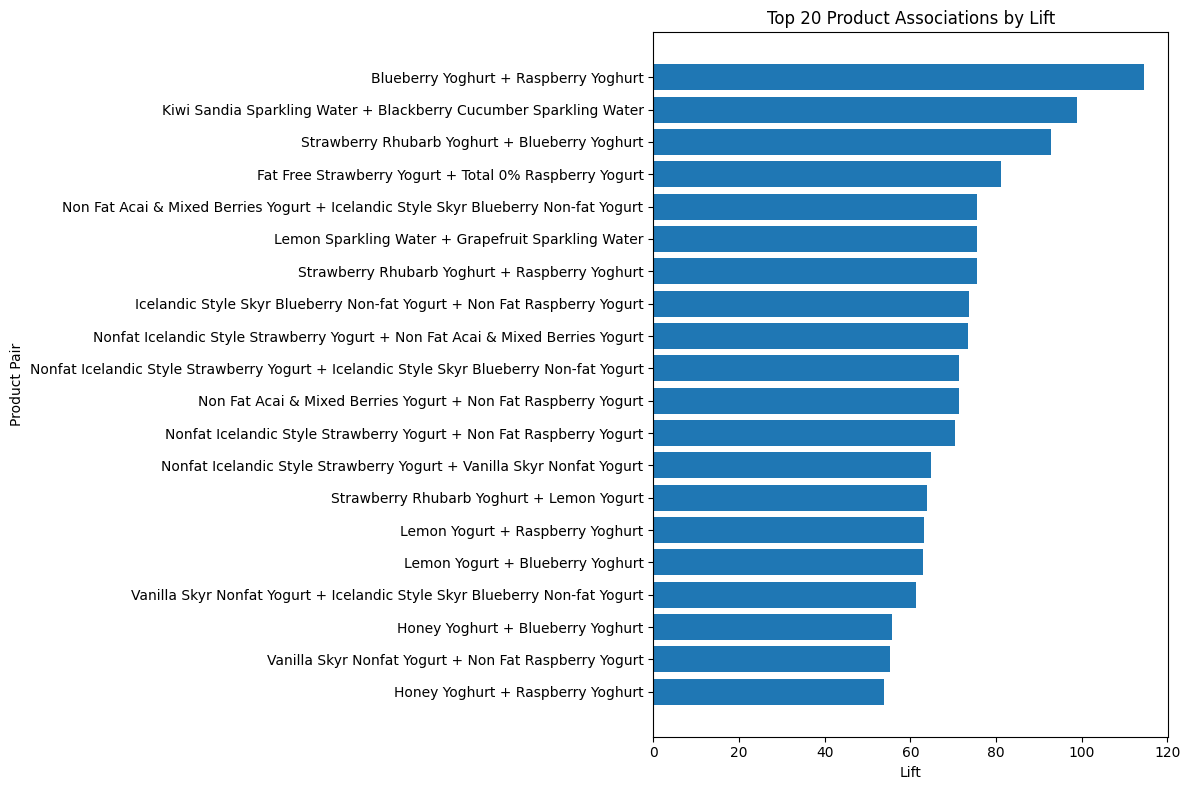

In [22]:
top_lift["product_pair"] = (
    top_lift["product_name_a"] + " + " +
    top_lift["product_name_b"]
)

plt.figure(figsize=(12, 8))

plt.barh(
    top_lift["product_pair"],
    top_lift["lift"]
)

plt.xlabel("Lift")
plt.ylabel("Product Pair")
plt.title("Top 20 Product Associations by Lift")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

## Aisle Analysis Product Pairs
1. Do customers tend to buy products from the same aisle together?
*   A products purchased in the same order from the same aisle? Limited to op 600 products purchased
*   Are top co-purchased items from the same aisle?


2. Which products from different aisles are strongly associated?

### Percentage of Top 600 Products in Aisle location

What is the percentage of your 600-product pair combinations come from the same aisle

In [23]:
product_aisles = (
    user_products[
        ["product_id", "aisle"]
    ]
    .drop_duplicates("product_id")
)

In [24]:
pair_counts = (
    pair_counts
    .merge(
        product_aisles.rename(
            columns={
                "product_id": "product_id_a",
                "aisle": "aisle_a"
            }
        ),
        on="product_id_a",
        how="left"
    )
    .merge(
        product_aisles.rename(
            columns={
                "product_id": "product_id_b",
                "aisle": "aisle_b"
            }
        ),
        on="product_id_b",
        how="left"
    )
)

In [25]:
pair_counts["same_aisle"] = (
    pair_counts["aisle_a"] == pair_counts["aisle_b"]
)
pair_counts.head(10)

,product_id_a,product_id_b,co_purchase_count,product_name_a,product_name_b,purchase_count_a,purchase_count_b,support,support_percent,confidence_a_to_b,confidence_a_to_b_percent,confidence_b_to_a,confidence_b_to_a_percent,lift,aisle_a,aisle_b,same_aisle
0,45,196,23,European Cucumber,Soda,18413,35791,0.000007,0.00,0.001249,0.12,0.000643,0.06,0.112,fresh vegetables,soft drinks,False
1,45,260,209,European Cucumber,Cantaloupe,18413,23900,0.000065,0.01,0.011351,1.14,0.008745,0.87,1.527,fresh vegetables,fresh fruits,False
2,45,329,98,European Cucumber,Organic Whole Grassmilk Milk,18413,15459,0.000030,0.00,0.005322,0.53,0.006339,0.63,1.107,fresh vegetables,milk,False
3,45,432,263,European Cucumber,Vanilla Almond Breeze Almond Milk,18413,30935,0.000082,0.01,0.014283,1.43,0.008502,0.85,1.484,fresh vegetables,soy lactosefree,False
4,45,651,97,European Cucumber,Organic Salted Butter,18413,15035,0.000030,0.00,0.005268,0.53,0.006452,0.65,1.126,fresh vegetables,butter,False
5,45,890,189,European Cucumber,Organic Diced Tomatoes,18413,21997,0.000059,0.01,0.010264,1.03,0.008592,0.86,1.500,fresh vegetables,canned jarred vegetables,False
6,45,1025,38,European Cucumber,Organic Fresh Basil,18413,11930,0.000012,0.00,0.002064,0.21,0.003185,0.32,0.556,fresh vegetables,fresh herbs,False
7,45,1158,183,European Cucumber,Mango Chunks,18413,17699,0.000057,0.01,0.009939,0.99,0.010340,1.03,1.805,fresh vegetables,frozen produce,False
8,45,1194,82,European Cucumber,Natural Artisan Water,18413,11110,0.000026,0.00,0.004453,0.45,0.007381,0.74,1.289,fresh vegetables,water seltzer sparkling water,False
9,45,1244,86,European Cucumber,Organic Orange Bell Pepper,18413,10518,0.000027,0.00,0.004671,0.47,0.008176,0.82,1.428,fresh vegetables,fresh vegetables,True


In [26]:
pair_counts["same_aisle"].value_counts()

,count
same_aisle,
False,164909
True,9009


In [27]:
pair_counts["same_aisle"].value_counts(normalize=True).mul(100).round(2)

,proportion
same_aisle,
False,94.82
True,5.18


### Top co-purchases and their aisle relationship

In [28]:
same_aisle_copurchases = pair_counts.loc[
    pair_counts["aisle_a"] == pair_counts["aisle_b"],
    "co_purchase_count"
].sum()

total_copurchases = pair_counts["co_purchase_count"].sum()

same_aisle_percent = (
    same_aisle_copurchases / total_copurchases
) * 100

In [29]:
print("Same-aisle co-purchases:", same_aisle_copurchases)
print("Total co-purchases:", total_copurchases)
print("Percentage of co-purchases from same aisle:", f"{same_aisle_percent:.2f}%")

Same-aisle co-purchases: 7581152
Total co-purchases: 55828269
Percentage of co-purchases from same aisle: 13.58%


In [30]:
print(top_lift.columns.tolist())

['product_id_a', 'product_id_b', 'co_purchase_count', 'product_name_a', 'product_name_b', 'purchase_count_a', 'purchase_count_b', 'support', 'support_percent', 'confidence_a_to_b', 'confidence_a_to_b_percent', 'confidence_b_to_a', 'confidence_b_to_a_percent', 'lift', 'product_pair']


In [31]:
product_aisles = (
    user_products[
        ["product_id", "aisle"]
    ]
    .drop_duplicates("product_id")
)

top_lift = (
    top_lift
    .merge(
        product_aisles.rename(
            columns={
                "product_id": "product_id_a",
                "aisle": "aisle_a"
            }
        ),
        on="product_id_a",
        how="left"
    )
    .merge(
        product_aisles.rename(
            columns={
                "product_id": "product_id_b",
                "aisle": "aisle_b"
            }
        ),
        on="product_id_b",
        how="left"
    )
)

In [32]:
same_aisle_top20 = top_lift.loc[
    top_lift["aisle_a"] == top_lift["aisle_b"],
    "co_purchase_count"
].sum()

total_top20_copurchases = top_lift["co_purchase_count"].sum()

same_aisle_top20_percent = (
    same_aisle_top20 /
    total_top20_copurchases
) * 100

print(
    "Percentage of top 20 lift co-purchases from same aisle:",
    f"{same_aisle_top20_percent:.2f}%"
)

Percentage of top 20 lift co-purchases from same aisle: 100.00%


### Products from different aisles with high co-purchase

In [33]:
different_aisle_pairs = pair_counts[
    pair_counts["aisle_a"] != pair_counts["aisle_b"]
].copy()

In [34]:
strong_cross_aisle_pairs = (
    different_aisle_pairs
    .sort_values("co_purchase_count", ascending=False)
)

strong_cross_aisle_pairs.head(20)

,product_id_a,product_id_b,co_purchase_count,product_name_a,product_name_b,purchase_count_a,purchase_count_b,support,support_percent,confidence_a_to_b,confidence_a_to_b_percent,confidence_b_to_a,confidence_b_to_a_percent,lift,aisle_a,aisle_b,same_aisle
116496,21903,24852,51395,Organic Baby Spinach,Banana,241921,472565,0.015987,1.60,0.212445,21.24,0.108758,10.88,1.445,packaged vegetables fruits,fresh fruits,False
71743,13176,21903,50372,Bag of Organic Bananas,Organic Baby Spinach,379450,241921,0.015668,1.57,0.132750,13.28,0.208217,20.82,1.764,fresh fruits,packaged vegetables fruits,False
71820,13176,27966,40503,Bag of Organic Bananas,Organic Raspberries,379450,137057,0.012599,1.26,0.106741,10.67,0.295519,29.55,2.504,fresh fruits,packaged vegetables fruits,False
110983,21137,21903,38134,Organic Strawberries,Organic Baby Spinach,264683,241921,0.011862,1.19,0.144074,14.41,0.157630,15.76,1.915,fresh fruits,packaged vegetables fruits,False
116781,21903,47209,34901,Organic Baby Spinach,Organic Hass Avocado,241921,213584,0.010856,1.09,0.144266,14.43,0.163406,16.34,2.171,packaged vegetables fruits,fresh fruits,False
111060,21137,27966,33863,Organic Strawberries,Organic Raspberries,264683,137057,0.010533,1.05,0.127938,12.79,0.247072,24.71,3.001,fresh fruits,packaged vegetables fruits,False
127406,24852,49683,32097,Banana,Cucumber Kirby,472565,97315,0.009984,1.00,0.067921,6.79,0.329826,32.98,2.244,fresh fruits,fresh vegetables,False
127140,24852,27845,31641,Banana,Organic Whole Milk,472565,137905,0.009842,0.98,0.066956,6.70,0.229441,22.94,1.561,fresh fruits,milk,False
116787,21903,47766,30889,Organic Baby Spinach,Organic Avocado,241921,176815,0.009608,0.96,0.127682,12.77,0.174697,17.47,2.322,packaged vegetables fruits,fresh fruits,False
71819,13176,27845,26481,Bag of Organic Bananas,Organic Whole Milk,379450,137905,0.008237,0.82,0.069788,6.98,0.192023,19.20,1.627,fresh fruits,milk,False


In [35]:
strong_pairs = different_aisle_pairs[
    (different_aisle_pairs["co_purchase_count"] >= 100) &
    (different_aisle_pairs["lift"] >= 2)
].copy()

In [36]:
strong_pairs = strong_pairs.sort_values(
    ["lift", "co_purchase_count"],
    ascending=[False, False]
)

strong_pairs.head(20)

,product_id_a,product_id_b,co_purchase_count,product_name_a,product_name_b,purchase_count_a,purchase_count_b,support,support_percent,confidence_a_to_b,confidence_a_to_b_percent,confidence_b_to_a,confidence_b_to_a_percent,lift,aisle_a,aisle_b,same_aisle
65518,11759,21573,1483,Organic Simply Naked Pita Chips,Roasted Pine Nut Hummus,8957,11381,0.000461,0.05,0.165569,16.56,0.130305,13.03,46.769,chips pretzels,fresh dips tapenades,False
149464,31651,37710,1366,Extra Fancy Unsalted Mixed Nuts,Trail Mix,9709,12068,0.000425,0.04,0.140694,14.07,0.113192,11.32,37.480,nuts seeds dried fruit,trail mix snack mix,False
162649,37710,41400,1126,Trail Mix,Crunchy Oats 'n Honey Granola Bars,12068,8723,0.000350,0.04,0.093305,9.33,0.129084,12.91,34.388,trail mix snack mix,energy granola bars,False
37666,6184,13575,4009,Clementines,Apples,30843,12575,0.001247,0.12,0.129981,13.00,0.318807,31.88,33.230,packaged produce,fresh fruits,False
133207,26348,41400,867,Mixed Fruit Fruit Snacks,Crunchy Oats 'n Honey Granola Bars,9955,8723,0.000270,0.03,0.087092,8.71,0.099392,9.94,32.098,fruit vegetable snacks,energy granola bars,False
65619,11759,37710,1058,Organic Simply Naked Pita Chips,Trail Mix,8957,12068,0.000329,0.03,0.118120,11.81,0.087670,8.77,31.467,chips pretzels,trail mix snack mix,False
149468,31651,38928,1238,Extra Fancy Unsalted Mixed Nuts,0% Greek Strained Yogurt,9709,13238,0.000385,0.04,0.127511,12.75,0.093519,9.35,30.966,nuts seeds dried fruit,yogurt,False
162638,37710,38928,1497,Trail Mix,0% Greek Strained Yogurt,12068,13238,0.000466,0.05,0.124047,12.40,0.113084,11.31,30.125,trail mix snack mix,yogurt,False
65577,11759,31651,778,Organic Simply Naked Pita Chips,Extra Fancy Unsalted Mixed Nuts,8957,9709,0.000242,0.02,0.086859,8.69,0.080132,8.01,28.761,chips pretzels,nuts seeds dried fruit,False
65623,11759,38928,1048,Organic Simply Naked Pita Chips,0% Greek Strained Yogurt,8957,13238,0.000326,0.03,0.117003,11.70,0.079166,7.92,28.415,chips pretzels,yogurt,False


### Co-Purchases sorted by Department

#### Initial Department Pairs without removal of duplicates

In [37]:
product_department = (
    user_products[["product_id", "department"]]
    .drop_duplicates()
)

In [38]:
pair_counts = pair_counts.merge(
    product_department,
    left_on="product_id_a",
    right_on="product_id",
    how="left"
).rename(columns={"department": "department_a"})

pair_counts = pair_counts.drop(columns=["product_id"])

In [39]:
pair_counts = pair_counts.merge(
    product_department,
    left_on="product_id_b",
    right_on="product_id",
    how="left"
).rename(columns={"department": "department_b"})

pair_counts = pair_counts.drop(columns=["product_id"])

In [40]:
# department-level co-purchases
department_pairs = (
    pair_counts
    .groupby(["department_a", "department_b"], as_index=False)
    ["co_purchase_count"]
    .sum()
)

# total department-pair co-purchases
total_department_copurchases = department_pairs["co_purchase_count"].sum()

# percent of total
department_pairs["percent_of_total"] = (
    department_pairs["co_purchase_count"]
    / total_department_copurchases
    * 100
).round(2)

# sort by strongest department pairs
department_pairs = department_pairs.sort_values(
    "co_purchase_count",
    ascending=False
)

department_pairs.head(10)

,department_a,department_b,co_purchase_count,percent_of_total
257,produce,produce,18755638,33.60
109,dairy eggs,produce,5693357,10.20
248,produce,dairy eggs,4991477,8.94
100,dairy eggs,dairy eggs,2220608,3.98
43,beverages,produce,1381460,2.47
159,frozen,produce,1276379,2.29
244,produce,beverages,1194030,2.14
274,snacks,produce,1032446,1.85
92,canned goods,produce,960787,1.72
249,produce,deli,870687,1.56


#### Removal of Same Department Purchases

In [41]:
cross_department_pairs = department_pairs[
    department_pairs["department_a"] != department_pairs["department_b"]
].copy()

In [42]:
total_cross_copurchases = cross_department_pairs["co_purchase_count"].sum()

cross_department_pairs["percent_of_total"] = (
    cross_department_pairs["co_purchase_count"]
    / total_cross_copurchases
    * 100
).round(2)

cross_department_pairs = cross_department_pairs.sort_values(
    "co_purchase_count",
    ascending=False
)

cross_department_pairs.head(10)

,department_a,department_b,co_purchase_count,percent_of_total
109,dairy eggs,produce,5693357,16.72
248,produce,dairy eggs,4991477,14.66
43,beverages,produce,1381460,4.06
159,frozen,produce,1276379,3.75
244,produce,beverages,1194030,3.51
274,snacks,produce,1032446,3.03
92,canned goods,produce,960787,2.82
249,produce,deli,870687,2.56
240,pantry,produce,848378,2.49
251,produce,frozen,839318,2.47


#### Removal of Cross Department Duplicates

In [43]:
pair_counts["department_pair"] = (
    pair_counts[["department_a", "department_b"]]
    .apply(lambda x: " ↔ ".join(sorted(x)), axis=1)
)

In [44]:
department_pairs = (
    pair_counts
    .groupby("department_pair", as_index=False)
    ["co_purchase_count"]
    .sum()
)

In [45]:
department_pairs = department_pairs[
    ~department_pairs["department_pair"].str.split(" ↔ ").apply(
        lambda x: x[0] == x[1]
    )
].copy()

In [46]:
total_copurchases = department_pairs["co_purchase_count"].sum()

department_pairs["percent_of_total"] = (
    department_pairs["co_purchase_count"]
    / total_copurchases
    * 100
).round(2)

In [47]:
department_pairs = department_pairs.sort_values(
    "co_purchase_count",
    ascending=False
).reset_index(drop=True)

department_pairs.head(10)

,department_pair,co_purchase_count,percent_of_total
0,dairy eggs ↔ produce,10684834,31.39
1,beverages ↔ produce,2575490,7.57
2,frozen ↔ produce,2115697,6.21
3,produce ↔ snacks,1703614,5.00
4,canned goods ↔ produce,1667677,4.90
5,deli ↔ produce,1642464,4.82
6,pantry ↔ produce,1530236,4.49
7,meat seafood ↔ produce,1214061,3.57
8,beverages ↔ dairy eggs,1033742,3.04
9,bakery ↔ produce,958148,2.81
